# Finding the Two Best Markets to Advertise in an E-learning Product

In this project, we'll aim to find the two best markets to advertise an E-learnng product in — we're working for an e-learning company that offers courses on programming. Most of our courses are on web and mobile development, but we also cover many other domains, like data science, game development, etc.

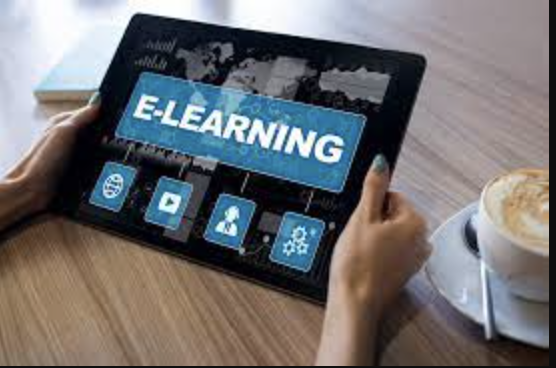

## Understanding the Data

To avoid spending money on organizing a survey, we'll first try to make use of existing data to determine whether we can reach any reliable result.

One good candidate for our purpose is [freeCodeCamp's 2018 New Coder Survey](https://www.freecodecamp.org/news/we-asked-20-000-people-who-they-are-and-how-theyre-learning-to-code-fff5d668969). [freeCodeCamp](https://www.freecodecamp.org/) is a free e-learning platform that offers courses on web development. Because they run a popular [Medium publication](https://www.freecodecamp.org/news/) (over 400,000 followers), their survey attracted new coders with varying interests (not only web development), which is ideal for the purpose of our analysis.

The survey data is publicly available in this [GitHub repository](https://github.com/freeCodeCamp/2017-new-coder-survey). Below, we'll do a quick exploration of the ```2017-fCC-New-Coders-Survey-Data.csv``` file stored in the ```clean-data folder``` of the repository we just mentioned. We'll read in the file using the direct link here.

### Import and Exploration of Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.style as style
%matplotlib inline

In [2]:
import pandas as pd
direct_link = 'https://raw.githubusercontent.com/freeCodeCamp/2017-new-coder-survey/master/clean-data/2017-fCC-New-Coders-Survey-Data.csv'
fcc = pd.read_csv(direct_link, low_memory = 0) # low_memory = False to silence dtypes warning

# Quick exploration of the data
print(fcc.shape)
pd.options.display.max_columns = 150 # to avoid truncated output 
fcc.head()

(18175, 136)


,Age,AttendedBootcamp,BootcampFinish,BootcampLoanYesNo,BootcampName,BootcampRecommend,ChildrenNumber,CityPopulation,CodeEventConferences,CodeEventDjangoGirls,CodeEventFCC,CodeEventGameJam,CodeEventGirlDev,CodeEventHackathons,CodeEventMeetup,CodeEventNodeSchool,CodeEventNone,CodeEventOther,CodeEventRailsBridge,CodeEventRailsGirls,CodeEventStartUpWknd,CodeEventWkdBootcamps,CodeEventWomenCode,CodeEventWorkshops,CommuteTime,CountryCitizen,CountryLive,EmploymentField,EmploymentFieldOther,EmploymentStatus,EmploymentStatusOther,ExpectedEarning,FinanciallySupporting,FirstDevJob,Gender,GenderOther,HasChildren,HasDebt,HasFinancialDependents,HasHighSpdInternet,HasHomeMortgage,HasServedInMilitary,HasStudentDebt,HomeMortgageOwe,HoursLearning,ID.x,ID.y,Income,IsEthnicMinority,IsReceiveDisabilitiesBenefits,IsSoftwareDev,IsUnderEmployed,JobApplyWhen,JobInterestBackEnd,JobInterestDataEngr,JobInterestDataSci,JobInterestDevOps,JobInterestFrontEnd,JobInterestFullStack,JobInterestGameDev,JobInterestInfoSec,JobInterestMobile,JobInterestOther,JobInterestProjMngr,JobInterestQAEngr,JobInterestUX,JobPref,JobRelocateYesNo,JobRoleInterest,JobWherePref,LanguageAtHome,MaritalStatus,MoneyForLearning,MonthsProgramming,NetworkID,Part1EndTime,Part1StartTime,Part2EndTime,Part2StartTime,PodcastChangeLog,PodcastCodeNewbie,PodcastCodePen,PodcastDevTea,PodcastDotNET,PodcastGiantRobots,PodcastJSAir,PodcastJSJabber,PodcastNone,PodcastOther,PodcastProgThrowdown,PodcastRubyRogues,PodcastSEDaily,PodcastSERadio,PodcastShopTalk,PodcastTalkPython,PodcastTheWebAhead,ResourceCodecademy,ResourceCodeWars,ResourceCoursera,ResourceCSS,ResourceEdX,ResourceEgghead,ResourceFCC,ResourceHackerRank,ResourceKA,ResourceLynda,ResourceMDN,ResourceOdinProj,ResourceOther,ResourcePluralSight,ResourceSkillcrush,ResourceSO,ResourceTreehouse,ResourceUdacity,ResourceUdemy,ResourceW3S,SchoolDegree,SchoolMajor,StudentDebtOwe,YouTubeCodeCourse,YouTubeCodingTrain,YouTubeCodingTut360,YouTubeComputerphile,YouTubeDerekBanas,YouTubeDevTips,YouTubeEngineeredTruth,YouTubeFCC,YouTubeFunFunFunction,YouTubeGoogleDev,YouTubeLearnCode,YouTubeLevelUpTuts,YouTubeMIT,YouTubeMozillaHacks,YouTubeOther,YouTubeSimplilearn,YouTubeTheNewBoston
0,27.0,0.0,NaN,NaN,NaN,NaN,NaN,more than 1 million,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15 to 29 minutes,Canada,Canada,software development and IT,NaN,Employed for wages,NaN,NaN,NaN,NaN,female,NaN,NaN,1.0,0.0,1.0,0.0,0.0,0.0,NaN,15.0,02d9465b21e8bd09374b0066fb2d5614,eb78c1c3ac6cd9052aec557065070fbf,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,start your own business,NaN,NaN,NaN,English,married or domestic partnership,150.0,6.0,6f1fbc6b2b,2017-03-09 00:36:22,2017-03-09 00:32:59,2017-03-09 00:59:46,2017-03-09 00:36:26,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,"some college credit, no degree",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,34.0,0.0,NaN,NaN,NaN,NaN,NaN,"less than 100,000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,United States of America,United States of America,NaN,NaN,Not working but looking for work,NaN,35000.0,NaN,NaN,male,NaN,NaN,1.0,0.0,1.0,0.0,0.0,1.0,NaN,10.0,5bfef9ecb211ec4f518cfc1d2a6f3e0c,21db37adb60cdcafadfa7dca1b13b6b1,NaN,0.0,0.0,0.0,NaN,Within 7 to 12 months,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,work for a nonprofit,1.0,Full-Stack Web Developer,in an office with other developers,English,"single, never married",80.0,6.0,f8f8be6910,2017-03-09 00:37:07,2017-03-09 00:33:26,2017-03-09 00:38:59,2017-03-09 00:37:10,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,1.0,"some college credit, no degree",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,21.0,0.0,NaN,NaN,NaN,NaN,NaN,more than 1 million,NaN,NaN,NaN,

## Checking for Sample Representativity

As we mentioned in the introduction, most of our courses are on web and mobile development, but we also cover many other domains, like data science, game development, etc. For the purpose of our analysis, we want to answer questions about a population of new coders that are interested in the subjects we teach. We'd like to know:

* Where are these new coders located.
* What locations have the greatest densities of new coders.
* How much money they're willing to spend on learning.

So we first need to clarify whether the data set has the right categories of people for our purpose. The ```JobRoleInterest``` column describes for every participant the role(s) they'd be interested in working in. If a participant is interested in working in a certain domain, it means that they're also interested in learning about that domain. So let's take a look at the frequency distribution table of this column and determine whether the data we have is relevant.

In [3]:
# Frequency distribution table for 'JobRoleInterest'
data = fcc['JobRoleInterest'].value_counts(normalize = True) * 100

# Display the frequency tables in a more readable format
jobroleper = pd.DataFrame(data = data)
jobroleper.columns = ['Job/Role Interest %']
jobroleper

,Job/Role Interest %
Full-Stack Web Developer,11.770595
Front-End Web Developer,6.435927
Data Scientist,2.173913
Back-End Web Developer,2.030892
Mobile Developer,1.673341
...,...
"Front-End Web Developer, DevOps / SysAdmin, Mobile Developer, Full-Stack Web Developer",0.014302
"Back-End Web Developer, Front-End Web Developer, Data Engineer, Full-Stack Web Developer, Mobile Developer",0.014302
"Back-End Web Developer, User Experience Designer, Mobile Developer, Game Developer, Front-End Web Developer, Full-Stack Web Developer",0.014302
"Front-End Web Developer, Mobile Developer, Back-End Web Developer, Full-Stack Web Developer, Data Engineer",0.014302


Let's clean it up to remove null values and to return only the first job interest for respondants with multiple answers 

In [4]:
job_interest = fcc['JobRoleInterest'].dropna() #removes all null values 
job_interest = job_interest.str.split(',').str[0] #returns only the first job interest for respondents with multiple interest
job_interest_frequency = job_interest.value_counts(normalize=True).head(20)*100 #returns the percentage of the top 20 job interests.
job_interest_frequency

Full-Stack Web Developer        24.427918
  Front-End Web Developer       17.820366
Back-End Web Developer          11.084096
  Mobile Developer               8.152174
  Data Scientist                 7.479977
Game Developer                   6.664760
  User Experience Designer       5.592105
Information Security             4.862700
Data Engineer                    4.347826
  DevOps / SysAdmin              3.318078
  Product Manager                3.060641
  Quality Assurance Engineer     1.558924
Software Engineer                0.071510
Software Developer               0.057208
undecided                        0.028604
Not sure                         0.028604
Not sure yet                     0.028604
Artificial Intelligence          0.028604
Unsure                           0.028604
Systems Programmer               0.014302
Name: JobRoleInterest, dtype: float64

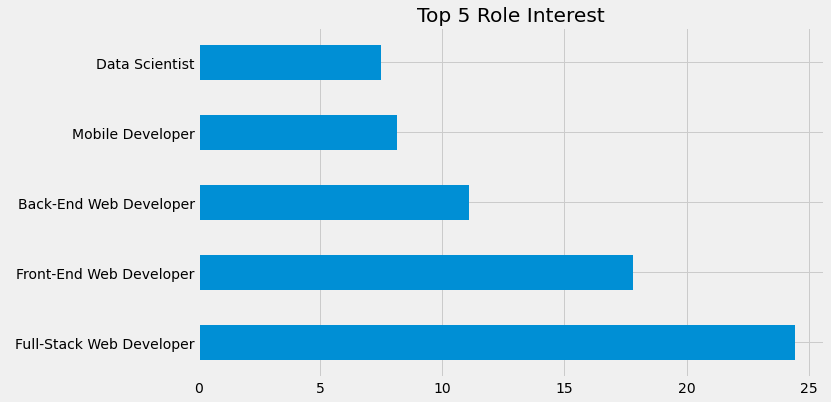

In [5]:
style.use('fivethirtyeight')
job_interest_frequency.head().plot.barh(width=0.5, figsize=(10, 6))
plt.title('Top 5 Role Interest')
plt.show()

The top 5 roles people were interested in were full-stack web development, front-end web development, back-end web development, mobie development and data science. Other roles included were game development, user experience designer, information security, etc.

It is important to note that many respondents are interested in more than one subject. It'd be useful to get a better picture of how many people are interested in a single subject and how many have mixed interests. Consequently, in the next code block, we'll:

In [6]:
# Split each string in the 'JobRoleInterest' column
interests_no_nulls = fcc['JobRoleInterest'].dropna()
splitted_interests = interests_no_nulls.str.split(',')

# Frequency table for the var describing the number of options
n_of_options = splitted_interests.apply(lambda x: len(x)) # x is a list of job options
n_of_options.value_counts(normalize = True).sort_index() * 100

1     31.650458
2     10.883867
3     15.889588
4     15.217391
5     12.042334
6      6.721968
7      3.861556
8      1.759153
9      0.986842
10     0.471968
11     0.185927
12     0.300343
13     0.028604
Name: JobRoleInterest, dtype: float64

It turns out that only 31.7% of the participants have a clear idea about what programming niche they'd like to work in, while the vast majority of students have mixed interests. But given that we offer courses on various subjects, the fact that new coders have mixed interest might be actually good for us.

The focus of our courses is on web and mobile development, so let's find out how many respondents chose at least one of these two options.

True     86.241419
False    13.758581
Name: JobRoleInterest, dtype: float64


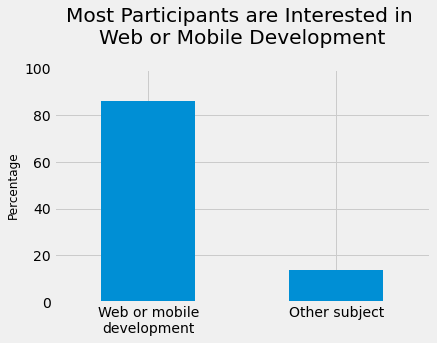

In [7]:
# Frequency table
web_or_mobile = interests_no_nulls.str.contains(
    'Web Developer|Mobile Developer') # returns an array of booleans
freq_table = web_or_mobile.value_counts(normalize = True) * 100
print(freq_table)

# Graph for the frequency table above
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

freq_table.plot.bar()
plt.title('Most Participants are Interested in \nWeb or Mobile Development',
          y = 1.08) # y pads the title upward
plt.ylabel('Percentage', fontsize = 12)
plt.xticks([0,1],['Web or mobile\ndevelopment', 'Other subject'],
           rotation = 0) # the initial xtick labels were True and False
plt.ylim([0,100])
plt.show()

It turns out that most people in this survey (roughly 86%) are interested in either web or mobile development. These figures offer us a strong reason to consider this sample representative for our population of interest. We want to advertise our courses to people interested in all sorts of programming niches but mostly web and mobile development.

Now we need to figure out what are the best markets to invest money in for advertising our courses. We'd like to know:

* Where are these new coders located.
* What are the locations with the greatest number of new coders.
* How much money new coders are willing to spend on learning.

## New Coders - Locations and Densities

Let's begin with finding out where these new coders are located, and what are the densities (how many new coders there are) for each location. This should be a good start for finding out the best two markets to run our ads campaign in.

The data set provides information about the location of each participant at a country level. We can think of each country as an individual market, so we can frame our goal as finding the two best countries to advertise in.

We can start by examining the frequency distribution table of the CountryLive variable, which describes what country each participant lives in (not their origin country). We'll only consider those participants who answered what role(s) they're interested in, to make sure we work with a representative sample.

In [8]:
# Isolate the participants that answered what role they'd be interested in
fcc_good = fcc[fcc['JobRoleInterest'].notnull()].copy()

# Frequency tables with absolute and relative frequencies
absolute_frequencies = fcc_good['CountryLive'].value_counts()
relative_frequencies = fcc_good['CountryLive'].value_counts(normalize = True) * 100

# Display the frequency tables in a more readable format
pd.DataFrame(data = {'Absolute frequency': absolute_frequencies, 
                     'Percentage': relative_frequencies}
            )

,Absolute frequency,Percentage
United States of America,3125,45.700497
India,528,7.721556
United Kingdom,315,4.606610
Canada,260,3.802281
Poland,131,1.915765
...,...,...
Liberia,1,0.014624
Papua New Guinea,1,0.014624
Guadeloupe,1,0.014624
Gibraltar,1,0.014624


45.7% of our potential customers are located in the US, and this definitely seems like the most interesting market. India has the second customer density, but it's just 7.7%, which is not too far from the United Kingdom (4.6%) or Canada (3.8%).

This is useful information, but we need to go more in depth than this and figure out how much money people are actually willing to spend on learning. Advertising in high-density markets where most people are only willing to learn for free is extremely unlikely to be profitable for us.

## Spending Money for Learning

The ```MoneyForLearning``` column describes in American dollars the amount of money spent by participants from the moment they started coding until the moment they completed the survey. Our company sells subscriptions at a price of $59 per month, and for this reason we're interested in finding out how much money each student spends per month.

We'll narrow down our analysis to five countries: the US, India, the United Kingdom, Canada, and Australia. We do this for two reasons:

These are the countries having the highest frequency in the frequency table above, which means we have a decent amount of data for each.

Our courses are written in English, and English is an official language in all these four countries. The more people know English, the better our chances to target the right people with our ads.

Let's start with creating a new column that describes the amount of money a student has spent per month so far. To do that, we'll need to divide the MoneyForLearning column to the MonthsProgramming column. 

First, we need to fix the 0 values in the ```MoneyForLearning``` column. Some students answered that they have been learning to code for 0 months (it might be that they have just started). To avoid dividing by 0, we'll replace 0 with 1 in the MonthsProgramming column.

In [9]:
# Replace 0s with 1s to avoid division by 0
fcc_good['MonthsProgramming'].replace(0,1, inplace = True)

# New column for the amount of money each student spends each month
fcc_good['money_per_month'] = fcc_good['MoneyForLearning'] / fcc_good['MonthsProgramming']
fcc_good['money_per_month'].isnull().sum()

675

In [10]:
# Keep only the rows with non-nulls in the `money_per_month` column 
fcc_good = fcc_good[fcc_good['money_per_month'].notnull()]

We want to group the data by country, and then measure the average amount of money that students spend per month in each country. First, let's remove the rows having null values for the ```CountryLive``` column, and check out if we still have enough data for the four countries that interest us.



In [11]:
# Remove the rows with null values in 'CountryLive'
fcc_good = fcc_good[fcc_good['CountryLive'].notnull()]

# Frequency table to check if we still have enough data
fcc_good['CountryLive'].value_counts().head()

United States of America    2933
India                        463
United Kingdom               279
Canada                       240
Poland                       122
Name: CountryLive, dtype: int64

In [12]:
country_grp = fcc_good.groupby('CountryLive')
country_mean_amount = pd.DataFrame({'mean_amount':country_grp['money_per_month'].mean()}).reset_index()

#getting our country of interest
interest_countries = country_mean_amount[(country_mean_amount['CountryLive'] == 'United States of America')
                                         | (country_mean_amount['CountryLive'] == 'India')
                                         | (country_mean_amount['CountryLive'] == 'United Kingdom')
                                         | (country_mean_amount['CountryLive'] == 'Canada')
                                         | (country_mean_amount['CountryLive'] == 'Australia')]

interest_countries.sort_values('mean_amount', ascending=False)

,CountryLive,mean_amount
6,Australia,419.268452
122,United States of America,227.997996
52,India,135.100982
19,Canada,113.510961
121,United Kingdom,45.534443


Our result shows that people in Australia spend the most money per month on average. However, the values for Canada and the United Kingdom are relatively low compared to the value for India. If we consider a few socio-economical metrics like GDP per capita, we would expect people in the United Kingdom and Canada to on average spend more than people in India. This might be because we don't have representative data for the United Kingdom, Canada, and India or we have some outliers making the mean for India too big or the mean for Canada and the United Kingdom too low.

## Dealing with Extreme Outliers

<frozen importlib._bootstrap>:228: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


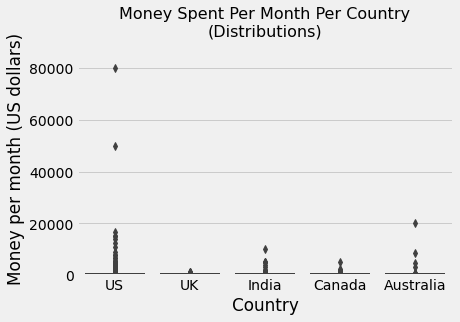

In [13]:
import seaborn as sns
filt = fcc_good['CountryLive'].str.contains('Australia|United States of America|India|Canada|United Kingdom')
required = fcc_good[filt] # returns data of only countries we are interested in
sns.boxplot(data=required, x='CountryLive', y='money_per_month')
plt.title('Money Spent Per Month Per Country\n(Distributions)',
         fontsize = 16)
plt.ylabel('Money per month (US dollars)')
plt.ylim(0,90000)
plt.xlabel('Country')
plt.xticks(range(5), ['US', 'UK', 'India', 'Canada', 'Australia']) # avoids tick labels overlap
plt.show()

From our boxplot, we see that there is an extreme outlier for the US, with monthly spend of more than ```$20,000```. This amount is very unlikely. Also for Australia there is an outlier of ```$20,000```. We are going to get rid of these outliers and recompute the average monthly spend.

In [14]:
# Isolate only those participants who spend less than 10000 per month
fcc_good = fcc_good[fcc_good['money_per_month'] < 20000]

In [15]:
#groups the data by country and returns a dataframe
country_grp = fcc_good.groupby('CountryLive')
country_mean_amount = pd.DataFrame({'mean_amount':country_grp['money_per_month'].mean()}).reset_index()

#getting our country of interest
interest_countries = country_mean_amount[(country_mean_amount['CountryLive'] == 'United States of America')
                                         | (country_mean_amount['CountryLive'] == 'India')
                                         | (country_mean_amount['CountryLive'] == 'United Kingdom')
                                         | (country_mean_amount['CountryLive'] == 'Canada')
                                         | (country_mean_amount['CountryLive'] == 'Australia')]
interest_countries

,CountryLive,mean_amount
6,Australia,225.399823
19,Canada,113.510961
52,India,135.100982
121,United Kingdom,45.534443
122,United States of America,183.800110


After getting rid of the outliers, the average amount spent has dropped for both the United States and Australia. We are goig to generate another boxplot to identify more outlier data

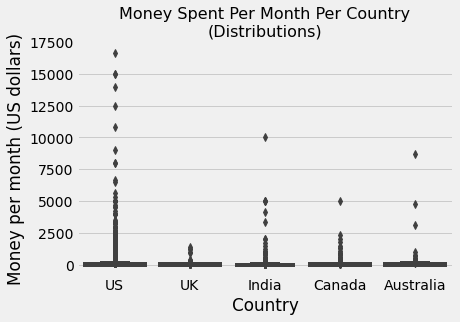

In [16]:
filt = fcc_good['CountryLive'].str.contains('Australia|United States of America|India|Canada|United Kingdom')
required = fcc_good[filt] # returns data of only countries we are interested in
sns.boxplot(data=required, x='CountryLive', y='money_per_month')
plt.title('Money Spent Per Month Per Country\n(Distributions)',
         fontsize = 16)
plt.ylabel('Money per month (US dollars)')
plt.xlabel('Country')
plt.xticks(range(5), ['US', 'UK', 'India', 'Canada', 'Australia']) # avoids tick labels overlap
plt.show()

From our newly generated boxplot, we can see that any amount above ```$2,000``` in India is an outlier. We will also treat amounts above ```$2,000``` as outliers in Australia too. One way to justify that amount is to find out if participants who paid over ```$2,000``` attended bootcamps, as bootcamps tend to be quite expensive.

## Checking for bootcamp attendance

In [17]:
filt = (required['CountryLive'] == 'India') & (required['money_per_month'] > 2000)
india_outlier = required[filt]
india_outlier[['CountryLive','Age', 'AttendedBootcamp', 'BootcampName',
               'MoneyForLearning', 'MonthsProgramming', 'money_per_month']]

,CountryLive,Age,AttendedBootcamp,BootcampName,MoneyForLearning,MonthsProgramming,money_per_month
1728,India,24.0,0.0,NaN,20000.0,4.0,5000.000000
1755,India,20.0,0.0,NaN,50000.0,15.0,3333.333333
7989,India,28.0,0.0,NaN,5000.0,1.0,5000.000000
8126,India,22.0,0.0,NaN,5000.0,1.0,5000.000000
13398,India,19.0,0.0,NaN,20000.0,2.0,10000.000000
15587,India,27.0,0.0,NaN,100000.0,24.0,4166.666667


It seems that neither participant attended a bootcamp. Overall, it's really hard to figure out from the data whether these persons really spent that much money with learning. The actual question of the survey was "Aside from university tuition, about how much money have you spent on learning to code so far (in US dollars)?", so they might have misunderstood and thought university tuition is included. It seems safer to remove these two rows.

In [18]:
required = required.drop(india_outlier.index) # removes every row with the same index as india_outlier 

In [19]:
filt = (required['CountryLive'] == 'Australia') & (required['money_per_month'] > 2000)
australia_outlier = required[filt]
australia_outlier[['CountryLive','Age', 'AttendedBootcamp', 'BootcampName',
               'MoneyForLearning', 'MonthsProgramming', 'money_per_month']]

,CountryLive,Age,AttendedBootcamp,BootcampName,MoneyForLearning,MonthsProgramming,money_per_month
88,Australia,24.0,1.0,Codemaster Institute,9600.0,2.0,4800.000000
3931,Australia,35.0,1.0,Coder Factory,26000.0,3.0,8666.666667
12810,Australia,23.0,1.0,Coder Factory,25000.0,8.0,3125.000000


In [20]:
required = required.drop(australia_outlier.index) # removes every row with the same index as australia_outlier

Despite the outlier data for Australia coming from those who attended bootcamps, none of the prices are representative of the average monthly price for a coding bootcamp and so the outlier rows for Australia were dropped.

In [21]:
filt = (required['CountryLive'] == 'United States of America') & (required['money_per_month'] > 6000)
us_outlier = required[filt]
us_outlier[['CountryLive','Age', 'AttendedBootcamp', 'BootcampName',
               'MoneyForLearning', 'MonthsProgramming', 'money_per_month']]

,CountryLive,Age,AttendedBootcamp,BootcampName,MoneyForLearning,MonthsProgramming,money_per_month
718,United States of America,26.0,1.0,The Coding Boot Camp at UCLA Extension,8000.0,1.0,8000.000000
1222,United States of America,32.0,1.0,The Iron Yard,13000.0,2.0,6500.000000
3184,United States of America,34.0,1.0,We Can Code IT,9000.0,1.0,9000.000000
3930,United States of America,31.0,0.0,NaN,65000.0,6.0,10833.333333
6805,United States of America,46.0,1.0,Sabio.la,15000.0,1.0,15000.000000
7198,United States of America,32.0,0.0,NaN,70000.0,5.0,14000.000000
7505,United States of America,26.0,1.0,Codeup,20000.0,3.0,6666.666667
9778,United States of America,33.0,1.0,Grand Circus,8000.0,1.0,8000.000000
16650,United States of America,29.0,0.0,NaN,200000.0,12.0,16666.666667
16997,United States of America,27.0,0.0,NaN,12500.0,1.0,12500.000000


Out of these 11 extreme outliers, six people attended bootcamps, which justify the large sums of money spent on learning. For the other five, it's hard to figure out from the data where they could have spent that much money on learning. Consequently, we'll remove those rows where participants reported thay they spend $6000 each month, but they have never attended a bootcamp.

Also, the data shows that eight respondents had been programming for no more than three months when they completed the survey. They most likely paid a large sum of money for a bootcamp that was going to last for several months, so the amount of money spent per month is unrealistic and should be significantly lower (because they probably didn't spend anything for the next couple of months after the survey). As a consequence, we'll remove every these eight outliers.

In the next code block, we'll remove respondents that:

* Didn't attend bootcamps.
* Had been programming for three months or less when at the time they completed the survey.

In [22]:
filt = (required['CountryLive'] == 'United States of America') & (required['money_per_month'] > 6000) & (required['AttendedBootcamp'] == 0)
us_outlier = required[filt]
us_outlier[['CountryLive','Age', 'AttendedBootcamp', 'BootcampName',
               'MoneyForLearning', 'MonthsProgramming', 'money_per_month']]

required = required.drop(us_outlier.index) # removes every row with the same index as us_outlier

In [23]:
filt = (required['CountryLive'] == 'United States of America') & (required['money_per_month'] > 6000) & (required['AttendedBootcamp'] <= 3)
us_outlier = required[filt]
us_outlier[['CountryLive','Age', 'AttendedBootcamp', 'BootcampName',
               'MoneyForLearning', 'MonthsProgramming', 'money_per_month']]

required = required.drop(us_outlier.index) # removes every row with the same index as us_outlier

In [24]:
filt = (required['CountryLive'] == 'Canada') & (required['money_per_month'] > 4000)
canada_outlier = required[filt]
canada_outlier[['CountryLive', 'AttendedBootcamp', 'BootcampName',
               'MoneyForLearning', 'MonthsProgramming', 'money_per_month']]

,CountryLive,AttendedBootcamp,BootcampName,MoneyForLearning,MonthsProgramming,money_per_month
13659,Canada,1.0,Bloc.io,10000.0,2.0,5000.0


Here, the situation is similar to some of the US respondents — this participant had been programming for no more than two months when he completed the survey. He seems to have paid a large sum of money in the beginning to enroll in a bootcamp, and then he probably didn't spend anything for the next couple of months after the survey. We'll take the same approach here as for the US and remove this outlier.

In [25]:
required = required.drop(canada_outlier.index) # removes every row with the same index as canada_outlier

In [26]:
#groups our data by countries and returns the mean amount spnt
interest_grp = required.groupby('CountryLive')
interest_mean_amount = pd.DataFrame({'mean_amount':interest_grp['money_per_month'].mean()}).reset_index()
interest_mean_amount['mean_amount'] = round(interest_mean_amount['mean_amount'], 2)
interest_mean_amount.sort_values('mean_amount', ascending=False)

,CountryLive,mean_amount
4,United States of America,142.65
1,Canada,93.07
2,India,65.76
0,Australia,63.00
3,United Kingdom,45.53


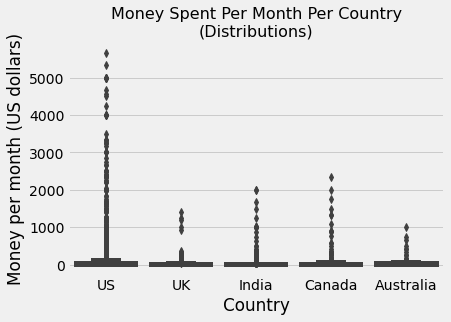

In [27]:
sns.boxplot(data=required, x='CountryLive', y='money_per_month')
plt.title('Money Spent Per Month Per Country\n(Distributions)',
         fontsize = 16)
plt.ylabel('Money per month (US dollars)')
plt.xlabel('Country')
plt.xticks(range(5), ['US', 'UK', 'India', 'Canada', 'Australia']) # avoids tick labels overlap
plt.show()

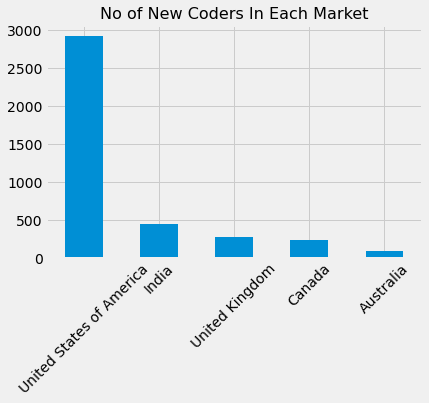

In [28]:
#Visualising the amount of new coders in our required market
required['CountryLive'].value_counts().plot.bar()
plt.xticks(rotation=45)
plt.title('No of New Coders In Each Market',
         size=16)
plt.show()

In [36]:
# Frequency table for the 'CountryLive' column
only_5 = fcc_good[fcc_good['CountryLive'].str.contains('Australia|United States of America|India|Canada|United Kingdom')]
only_5['CountryLive'].value_counts(normalize = True) * 100

United States of America    73.019432
India                       11.534629
United Kingdom               6.950673
Canada                       5.979073
Australia                    2.516193
Name: CountryLive, dtype: float64

4 out of the 5 markets we analysed are on average likely to meet our subscription demand of ```$59```. The best market to advertsise in is clearly the US, not only is the country with the most amount of new coders, coders in the US tend to spend the most money monthly on average. 

As a second market where to run advertisements, the data suggests strongly that we shouldn't advertise in the UK. On the other hand, further analysis should be done between Canada and India. Despite the average monthly spend being higher in Canada, the amount of new coders in India tilts it in a favourable direction. Likwise there are almost twice as more potential customers in India than in Canada.

## Conclusion

In this project, we analyzed survey data from new coders to find the best two markets to advertise in. The only solid conclusion we reached is that the US would be a good market to advertise in.


At this point, it seems that we have several options:

1. Advertise in the US, India, and Canada by splitting the advertisement budget in various combinations:

* 60% for the US, 25% for India, 15% for Canada.
* 50% for the US, 30% for India, 20% for Canada; etc.

2. Advertise only in the US and India, or the US and Canada. Again, it makes sense to split the advertisement budget unequally. For instance:

* 70% for the US, and 30% for India.
* 65% for the US, and 35% for Canada; etc.

3. Advertise only in the US.

For the second best market, it wasn't clear-cut what to choose between India and Canada. We decided to send the results to the marketing team so they can use their domain knowledge to take the best decision.
